# Cell 1 — Connect to MySQL


In [60]:
import pandas as pd
from sqlalchemy import create_engine, text

# XAMPP default: user=root, password=empty
engine = create_engine('mysql+mysqlconnector://root:@localhost/')

with engine.connect() as conn:
    conn.execute(text("CREATE DATABASE IF NOT EXISTS library_dw;"))
    conn.commit()
print(" Database 'library_dw' created")

# Reconnect to the specific database
engine = create_engine('mysql+mysqlconnector://root:@localhost/library_dw')
print(" Connected to library_dw")

 Database 'library_dw' created
 Connected to library_dw


# Cell 2 — Create the 3 Staging Tables (raw messy data lands here)

In [61]:
staging_ddl = """
DROP TABLE IF EXISTS staging_book_transactions;
CREATE TABLE staging_book_transactions (
    TransactionID INT,
    StudentID VARCHAR(20),
    BookISBN VARCHAR(20),
    CheckoutDate VARCHAR(30),
    ReturnDate VARCHAR(30),
    Department VARCHAR(50),
    BookCategory VARCHAR(50)
);

DROP TABLE IF EXISTS staging_digital_usage;
CREATE TABLE staging_digital_usage (
    `Date` VARCHAR(30),
    UserType VARCHAR(50),
    ResourceType VARCHAR(50),
    Faculty VARCHAR(50),
    DownloadCount VARCHAR(20),
    Duration_Minutes VARCHAR(20)
);

DROP TABLE IF EXISTS staging_room_bookings;
CREATE TABLE staging_room_bookings (
    BookingID INT,
    RoomNumber VARCHAR(20),
    BookingDate VARCHAR(30),
    TimeSlot VARCHAR(30),
    StudentID VARCHAR(20),
    DurationHours VARCHAR(20),
    Purpose VARCHAR(50)
);
"""

with engine.connect() as conn:
    for stmt in staging_ddl.strip().split(';'):
        if stmt.strip():
            conn.execute(text(stmt))
    conn.commit()
print(" Staging tables created")

 Staging tables created


# Cell 3 — Extract & Load (EL of ETL)

In [62]:
# --- Extract ---
books   = pd.read_csv('book_transactions.csv')
digital = pd.read_excel('digital_usage.xlsx')
rooms   = pd.read_csv('room_bookings.csv')

print(f"Books: {len(books)} rows")
print(f"Digital: {len(digital)} rows")
print(f"Rooms: {len(rooms)} rows")

Books: 625 rows
Digital: 400 rows
Rooms: 515 rows


# Cell 4 — Push to Staging Tables

In [63]:
books.to_sql('staging_book_transactions', engine, if_exists='replace', index=False)
digital.to_sql('staging_digital_usage', engine, if_exists='replace', index=False)
rooms.to_sql('staging_room_bookings', engine, if_exists='replace', index=False)

print(" All 3 source files loaded into staging")

 All 3 source files loaded into staging


# Quick sanity check — see the mess you're about to clean

In [64]:
pd.read_sql("SELECT * FROM staging_book_transactions LIMIT 5;", engine)



,TransactionID,StudentID,BookISBN,CheckoutDate,ReturnDate,Department,BookCategory
0,1000,STU-2024-161,978-1127978094,"Jan 30, 2024","Feb 03, 2024",CS,Textbook
1,1001,STU-2024-030,978-5951406973,"Sep 01, 2024",2024-09-20,CompSci,Fiction
2,1002,STU-2024-121,978-7483366056,"Feb 05, 2024",NaN,CompSci,Textbook
3,1003,STU-2024-215,978-9894847574,"May 06, 2024",2024-05-28,Bus,Textbook
4,1004,STU-2024-367,978-8235363119,09/24/2024,"Oct 03, 2024",ENG,Reference


#  STEP 3 — Data Quality Profiling (Before Cleaning)
# Cell 5 — Baseline metrics (required for your data quality report)

In [65]:
def profile(table, col=None):
    q = f"SELECT COUNT(*) AS total_rows FROM {table};"
    total = pd.read_sql(q, engine)['total_rows'][0]
    print(f"\n {table} — {total} rows")
    if col:
        q = f"SELECT COUNT(*) AS nulls FROM {table} WHERE `{col}` IS NULL OR `{col}`='';"
        nulls = pd.read_sql(q, engine)['nulls'][0]
        print(f"   Column '{col}': {nulls} NULLs ({nulls/total*100:.1f}%)")

profile('staging_book_transactions', 'ReturnDate')
profile('staging_book_transactions', 'Department')
profile('staging_digital_usage', 'Duration_Minutes')
profile('staging_room_bookings', 'StudentID')

# Duplicate check
dupes = pd.read_sql("""
    SELECT TransactionID, COUNT(*) AS c
    FROM staging_book_transactions
    GROUP BY TransactionID HAVING c > 1;
""", engine)
print(f"\n Duplicate TransactionIDs: {len(dupes)}")


 staging_book_transactions — 625 rows
   Column 'ReturnDate': 91 NULLs (14.6%)

 staging_book_transactions — 625 rows
   Column 'Department': 0 NULLs (0.0%)

 staging_digital_usage — 400 rows
   Column 'Duration_Minutes': 92 NULLs (23.0%)

 staging_room_bookings — 515 rows
   Column 'StudentID': 46 NULLs (8.9%)

 Duplicate TransactionIDs: 25


# Cell 6 — Clean Books

In [66]:
# --- BOOKS ---
books = pd.read_sql("SELECT * FROM staging_book_transactions;", engine)

# 1. Standardize department names
dept_map = {
    'CS': 'Computer Science', 'CompSci': 'Computer Science',
    'ENG': 'Engineering', 'Engr': 'Engineering',
    'MATH': 'Mathematics', 'Math': 'Mathematics',
    'BUS': 'Business', 'Bus': 'Business'
}
books['Department'] = books['Department'].replace(dept_map)

# 2. Fix CheckoutDate (mixed formats) → ISO YYYY-MM-DD
books['CheckoutDate'] = pd.to_datetime(books['CheckoutDate'], errors='coerce', dayfirst=False)
books['ReturnDate']   = pd.to_datetime(books['ReturnDate'], errors='coerce', dayfirst=False)

# 3. Remove duplicates on TransactionID (keep first)
before = len(books)
books = books.drop_duplicates(subset=['TransactionID'], keep='first')
print(f"Books: removed {before - len(books)} duplicate rows")

# 4. Flag not-returned books (ReturnDate is NULL)
books['is_returned'] = books['ReturnDate'].notna()

# 5. Calculate loan duration
books['loan_days'] = (books['ReturnDate'] - books['CheckoutDate']).dt.days

# Write clean version back to staging
books_clean = books.copy()
books_clean['CheckoutDate'] = books_clean['CheckoutDate'].dt.strftime('%Y-%m-%d')
books_clean['ReturnDate']   = books_clean['ReturnDate'].dt.strftime('%Y-%m-%d')
books_clean = books_clean.astype(object).where(pd.notna(books_clean), None)
books_clean.to_sql('staging_book_transactions', engine, if_exists='replace', index=False)
print(" Books cleaned")

Books: removed 25 duplicate rows
 Books cleaned


# Cell 7 — Clean Digital

In [67]:
# --- DIGITAL (Fixed for newer Pandas) ---
digital = pd.read_sql("SELECT * FROM staging_digital_usage;", engine)

# 1. Standardize Faculty
fac_map = {
    'ENG': 'Engineering', 'Engr': 'Engineering',
    'CS': 'Computer Science', 'CompSci': 'Computer Science',
    'BUS': 'Business', 'Bus': 'Business'
}
digital['Faculty'] = digital['Faculty'].replace(fac_map)

# 2. Standardize ResourceType
rt_map = {'E-book': 'E-book', 'e-Book': 'E-book', 'E-BOOK': 'E-book',
          'JOURNAL': 'Journal', 'journal': 'Journal'}
digital['ResourceType'] = digital['ResourceType'].replace(rt_map)

# 3. Standardize UserType
digital['UserType'] = digital['UserType'].str.title()

# 4. Parse mixed date formats → ISO 
# FIXED LINE BELOW: using format='mixed' instead of infer_datetime_format
digital['Date'] = pd.to_datetime(digital['Date'], format='mixed', errors='coerce')
digital['Date'] = digital['Date'].dt.strftime('%Y-%m-%d')

# 5. DownloadCount: strip commas, cast to int
digital['DownloadCount'] = digital['DownloadCount'].astype(str).str.replace(',', '')
digital['DownloadCount'] = pd.to_numeric(digital['DownloadCount'], errors='coerce').fillna(0).astype(int)

# 6. Duration_Minutes: keep NULL (do not impute — legacy missing)
digital['Duration_Minutes'] = pd.to_numeric(digital['Duration_Minutes'], errors='coerce')

# 7. Dedup
before = len(digital)
digital = digital.drop_duplicates(subset=['Date','UserType','ResourceType','Faculty'])
print(f"Digital: removed {before - len(digital)} duplicates")

digital_clean = digital.astype(object).where(pd.notna(digital), None)
digital_clean.to_sql('staging_digital_usage', engine, if_exists='replace', index=False)
print(" Digital cleaned")

Digital: removed 10 duplicates
 Digital cleaned


# Clean Rooms

In [68]:
# --- ROOMS ---
rooms = pd.read_sql("SELECT * FROM staging_room_bookings;", engine)

# 1. Standardize room numbers: R-101, Room101 → R101
import re
def fix_room(x):
    if pd.isna(x): return None
    digits = re.sub(r'[^0-9]', '', str(x))
    return f"R{digits}" if digits else None
rooms['RoomNumber'] = rooms['RoomNumber'].apply(fix_room)

# 2. Standardize TimeSlot
slot_map = {
    'Morning': 'Morning', 'AM': 'Morning', '8AM-10AM': 'Morning', '8-10': 'Morning',
    'Afternoon': 'Afternoon', 'PM': 'Afternoon', '2PM-4PM': 'Afternoon',
    'Evening': 'Evening', '6PM-8PM': 'Evening'
}
rooms['TimeSlot'] = rooms['TimeSlot'].replace(slot_map)

# 3. Parse BookingDate
rooms['BookingDate'] = pd.to_datetime(rooms['BookingDate'], errors='coerce')
rooms['BookingDate'] = rooms['BookingDate'].dt.strftime('%Y-%m-%d')

# 4. DurationHours → float
rooms['DurationHours'] = pd.to_numeric(rooms['DurationHours'], errors='coerce')

# 5. Dedup
before = len(rooms)
rooms = rooms.drop_duplicates(subset=['BookingID'], keep='first')
print(f"Rooms: removed {before - len(rooms)} duplicates")

# 6. Handle missing StudentID → "UNKNOWN"
rooms['StudentID'] = rooms['StudentID'].fillna('UNKNOWN')

rooms_clean = rooms.astype(object).where(pd.notna(rooms), None)
rooms_clean.to_sql('staging_room_bookings', engine, if_exists='replace', index=False)
print(" Rooms cleaned")

Rooms: removed 15 duplicates
 Rooms cleaned


#  STEP 5 — Build Dimension & Fact Tables              
#   Cell 9 — Create dimension tables

In [69]:
# We must drop the fact table FIRST because it has foreign keys pointing to the dimensions
drop_order = """
DROP TABLE IF EXISTS library_usage_fact;
DROP TABLE IF EXISTS dim_date;
DROP TABLE IF EXISTS dim_student;
DROP TABLE IF EXISTS dim_resource;
DROP TABLE IF EXISTS dim_room;
DROP TABLE IF EXISTS dim_time;
"""

create_tables = """
CREATE TABLE dim_date (
    date_key INT PRIMARY KEY,
    full_date DATE NOT NULL,
    year INT, quarter INT, month INT, day INT,
    day_name VARCHAR(10), is_weekend BOOLEAN
);

CREATE TABLE dim_student (
    student_key INT AUTO_INCREMENT PRIMARY KEY,
    student_id VARCHAR(20) UNIQUE,
    department VARCHAR(50),
    user_type VARCHAR(20)
);

CREATE TABLE dim_resource (
    resource_key INT AUTO_INCREMENT PRIMARY KEY,
    resource_id VARCHAR(50),
    resource_type VARCHAR(20),
    category VARCHAR(50)
);

CREATE TABLE dim_room (
    room_key INT AUTO_INCREMENT PRIMARY KEY,
    room_number VARCHAR(10) UNIQUE
);

CREATE TABLE dim_time (
    time_key INT PRIMARY KEY,
    time_slot VARCHAR(20),
    hour_block VARCHAR(20)
);

CREATE TABLE library_usage_fact (
    fact_key BIGINT AUTO_INCREMENT PRIMARY KEY,
    date_key INT,
    student_key INT,
    resource_key INT,
    room_key INT,
    time_key INT,
    download_count INT DEFAULT 0,
    duration_minutes INT DEFAULT 0,
    loan_days INT DEFAULT 0,
    duration_hours DECIMAL(5,2) DEFAULT 0,
    FOREIGN KEY (date_key) REFERENCES dim_date(date_key),
    FOREIGN KEY (student_key) REFERENCES dim_student(student_key),
    FOREIGN KEY (resource_key) REFERENCES dim_resource(resource_key),
    FOREIGN KEY (room_key) REFERENCES dim_room(room_key),
    FOREIGN KEY (time_key) REFERENCES dim_time(time_key)
);
"""

with engine.connect() as conn:
    # 1. Drop old tables in the correct order
    for stmt in drop_order.strip().split(';'):
        if stmt.strip():
            conn.execute(text(stmt))
            
    # 2. Create new tables
    for stmt in create_tables.strip().split(';'):
        if stmt.strip():
            conn.execute(text(stmt))
            
    conn.commit()

print(" All dimension + fact tables successfully recreated!")

 All dimension + fact tables successfully recreated!


# Cell 10 — Populate dim_date (2024 full year + 2025)

In [70]:
dates = pd.date_range('2024-01-01', '2025-12-31', freq='D')
dim_date_df = pd.DataFrame({
    'date_key':  dates.strftime('%Y%m%d').astype(int),
    'full_date': dates.date,
    'year':      dates.year,
    'quarter':   dates.quarter,
    'month':     dates.month,
    'day':       dates.day,
    'day_name':  dates.strftime('%A'),
    'is_weekend': dates.weekday >= 5
})
dim_date_df.to_sql('dim_date', engine, if_exists='append', index=False)
print(f" dim_date loaded: {len(dim_date_df)} dates")

 dim_date loaded: 731 dates


# Cell 11 — Populate dim_student

In [71]:
# Collect all unique students from books + rooms
students_b = books[['StudentID','Department']].rename(columns={'StudentID':'sid','Department':'dept'})
students_r = rooms[['StudentID']].rename(columns={'StudentID':'sid'})
students_r['dept'] = None
all_students = pd.concat([students_b, students_r]).dropna(subset=['sid'])
all_students = all_students.drop_duplicates(subset=['sid'])

# Assign user_type (simple heuristic — refine if needed)
all_students['user_type'] = 'Student'

dim_student_df = all_students.rename(columns={'sid':'student_id','dept':'department'})
dim_student_df = dim_student_df[['student_id','department','user_type']]
dim_student_df.to_sql('dim_student', engine, if_exists='append', index=False)
print(f" dim_student loaded: {len(dim_student_df)} students")

 dim_student loaded: 370 students


# Cell 12 — Populate dim_resource, dim_room, dim_time

In [72]:
# Resources: physical books + digital resources
book_res = books[['BookISBN','BookCategory']].rename(
    columns={'BookISBN':'resource_id','BookCategory':'category'})
book_res['resource_type'] = 'Physical Book'

digital_res = digital[['ResourceType']].drop_duplicates().rename(
    columns={'ResourceType':'resource_type'})
digital_res['resource_id'] = None
digital_res['category'] = digital_res['resource_type']

all_res = pd.concat([book_res, digital_res]).drop_duplicates(subset=['resource_id','resource_type'])
all_res = all_res.astype(object).where(pd.notna(all_res), None)
all_res.to_sql('dim_resource', engine, if_exists='append', index=False)
print(f" dim_resource loaded: {len(all_res)}")

# Rooms
dim_room_df = rooms[['RoomNumber']].dropna().drop_duplicates().rename(columns={'RoomNumber':'room_number'})
dim_room_df.to_sql('dim_room', engine, if_exists='append', index=False)
print(f" dim_room loaded: {len(dim_room_df)}")

# Time slots
time_df = pd.DataFrame([
    {'time_key':1,'time_slot':'Morning','hour_block':'08:00-12:00'},
    {'time_key':2,'time_slot':'Afternoon','hour_block':'12:00-18:00'},
    {'time_key':3,'time_slot':'Evening','hour_block':'18:00-22:00'},
    {'time_key':4,'time_slot':'Unknown','hour_block':'N/A'}
])
time_df.to_sql('dim_time', engine, if_exists='append', index=False)
print(f" dim_time loaded: {len(time_df)}")

 dim_resource loaded: 122
 dim_room loaded: 20
 dim_time loaded: 4


# Cell 13 — Populate the fact table (the big one)

In [73]:
# Clear fact table before loading to prevent duplicates on re-runs
with engine.connect() as conn:
    conn.execute(text("TRUNCATE TABLE library_usage_fact;"))
    conn.commit()

# Create mapping dictionaries for fast lookups
student_map = dict(zip(dim_student_df['student_id'], range(1, len(dim_student_df)+1)))
resource_map = dict(zip(all_res['resource_id'], range(1, len(all_res)+1)))
room_map = dict(zip(dim_room_df['room_number'], range(1, len(dim_room_df)+1)))

# ---------- BOOKS → FACT ----------
b = books.copy()
b['date_key']    = pd.to_datetime(b['CheckoutDate']).dt.strftime('%Y%m%d')
b['student_key'] = b['StudentID'].map(student_map)
b['resource_key'] = b['BookISBN'].map(resource_map)  # FIX: Map BookISBN to resource_key
b['loan_days']   = b['loan_days'].fillna(0)

book_facts = pd.DataFrame({
    'date_key': b['date_key'],
    'student_key': b['student_key'],
    'resource_key': b['resource_key'], # NOW POPULATED
    'room_key': None,
    'time_key': None,
    'download_count': 0,
    'duration_minutes': 0,
    'loan_days': b['loan_days'].astype(int),
    'duration_hours': 0
})

# ---------- DIGITAL → FACT ----------
d = digital.copy()
d['date_key']    = pd.to_datetime(d['Date']).dt.strftime('%Y%m%d')
digital_facts = pd.DataFrame({
    'date_key': d['date_key'],
    'student_key': None,
    'resource_key': None,
    'room_key': None,
    'time_key': None,
    'download_count': d['DownloadCount'].fillna(0).astype(int),
    'duration_minutes': d['Duration_Minutes'].fillna(0).astype(int),
    'loan_days': 0,
    'duration_hours': 0
})

# ---------- ROOMS → FACT ----------
r = rooms.copy()
r['date_key']    = pd.to_datetime(r['BookingDate']).dt.strftime('%Y%m%d')
r['student_key'] = r['StudentID'].map(student_map)
r['room_key']    = r['RoomNumber'].map(room_map)  # FIX: Map RoomNumber to room_key
r['time_key']    = r['TimeSlot'].map({'Morning':1,'Afternoon':2,'Evening':3}).fillna(4).astype(int)

room_facts = pd.DataFrame({
    'date_key': r['date_key'],
    'student_key': r['student_key'],
    'resource_key': None,
    'room_key': r['room_key'], # NOW POPULATED
    'time_key': r['time_key'],
    'download_count': 0,
    'duration_minutes': 0,
    'loan_days': 0,
    'duration_hours': r['DurationHours'].fillna(0)
})

# Combine and load
all_facts = pd.concat([book_facts, digital_facts, room_facts], ignore_index=True)
all_facts = all_facts.dropna(subset=['date_key'])
all_facts['date_key'] = all_facts['date_key'].astype(int)
all_facts = all_facts.astype(object).where(pd.notna(all_facts), None)

all_facts.to_sql('library_usage_fact', engine, if_exists='append', index=False)
print(f" Fact table loaded: {len(all_facts)} rows")

 Fact table loaded: 854 rows


# Cell 14 — Final sanity check

In [74]:
for t in ['dim_date','dim_student','dim_resource','dim_room','dim_time','library_usage_fact']:
    n = pd.read_sql(f"SELECT COUNT(*) AS c FROM {t};", engine)['c'][0]
    print(f"{t:25} → {n} rows")

dim_date                  → 731 rows
dim_student               → 370 rows


dim_resource              → 122 rows
dim_room                  → 20 rows
dim_time                  → 4 rows
library_usage_fact        → 854 rows


# STEP 6 — The 10 Business Queries
# Cell 15 — Q1: Monthly trends across all services

In [75]:
q1 = pd.read_sql("""
    SELECT d.year, d.month,
           SUM(f.loan_days)        AS physical_loan_days,
           SUM(f.download_count)   AS digital_downloads,
           SUM(f.duration_hours)   AS room_hours
    FROM library_usage_fact f
    JOIN dim_date d ON f.date_key = d.date_key
    GROUP BY d.year, d.month
    ORDER BY d.year, d.month;
""", engine)
q1

,year,month,physical_loan_days,digital_downloads,room_hours
0,2024,1,51.0,1118.0,55.3
1,2024,2,113.0,695.0,39.0
2,2024,3,68.0,847.0,59.2
3,2024,4,14.0,845.0,30.5
4,2024,5,118.0,737.0,74.8
5,2024,6,60.0,726.0,51.6
6,2024,7,81.0,1049.0,62.7
7,2024,8,113.0,740.0,55.8
8,2024,9,79.0,1066.0,50.0
9,2024,10,144.0,844.0,51.8


# Cell 16 — Q2: Department ranking

In [76]:
q2 = pd.read_sql("""
    SELECT s.department,
           COUNT(*) AS usage_events,
           SUM(f.download_count) AS downloads,
           SUM(f.loan_days) AS loan_days
    FROM library_usage_fact f
    JOIN dim_student s ON f.student_key = s.student_key
    WHERE s.department IS NOT NULL
    GROUP BY s.department
    ORDER BY usage_events DESC;
""", engine)
q2

,department,usage_events,downloads,loan_days
0,Computer Science,94,0.0,270.0
1,Business,89,0.0,298.0
2,Mathematics,74,0.0,157.0
3,Engineering,70,0.0,223.0
4,Physics,34,0.0,95.0
5,PHY,24,0.0,66.0


# Cell 17 — Q3: Peak times for room bookings

In [77]:
q3 = pd.read_sql("""
    SELECT t.time_slot, COUNT(*) AS bookings
    FROM library_usage_fact f
    JOIN dim_time t ON f.time_key = t.time_key
    WHERE f.time_key IS NOT NULL
    GROUP BY t.time_slot
    ORDER BY bookings DESC;
""", engine)
q3

,time_slot,bookings
0,Morning,124
1,Afternoon,101
2,Evening,32


# Cell 18 — Q4: Top 10 books

In [78]:
q4 = pd.read_sql("""
    SELECT r.resource_id AS BookISBN, r.category AS BookCategory, COUNT(*) AS times_borrowed
    FROM library_usage_fact f
    JOIN dim_resource r ON f.resource_key = r.resource_key
    WHERE r.resource_type = 'Physical Book'
    GROUP BY r.resource_id, r.category
    ORDER BY times_borrowed DESC
    LIMIT 10;
""", engine)
q4

,BookISBN,BookCategory,times_borrowed
0,978-8429141456,Textbook,7
1,978-1251837136,Fiction,5
2,978-5996775663,Reference,5
3,978-1083651970,Textbook,4
4,978-3479708607,Fiction,4
5,978-6924716023,Fiction,4
6,978-2181241943,Fiction,4
7,978-9285415473,Reference,4
8,978-4131575764,Reference,4
9,978-2067970820,Textbook,4


# Cell 19 — Q5: Avg loan duration by department

In [79]:
q5 = pd.read_sql("""
    SELECT s.department,
           ROUND(AVG(f.loan_days), 2) AS avg_loan_days,
           COUNT(*) AS loans
    FROM library_usage_fact f
    JOIN dim_student s ON f.student_key = s.student_key
    WHERE f.loan_days > 0 AND s.department IS NOT NULL
    GROUP BY s.department
    ORDER BY avg_loan_days DESC;
""", engine)
q5

,department,avg_loan_days,loans
0,Business,18.63,16
1,Engineering,17.15,13
2,PHY,16.50,4
3,Physics,15.83,6
4,Mathematics,15.70,10
5,Computer Science,14.21,19


# Cell 20 — Q6: OLAP Drill-down (Year → Quarter → Month)

In [80]:
q6 = pd.read_sql("""
    SELECT d.year, d.quarter, d.month, SUM(f.download_count) AS downloads
    FROM library_usage_fact f
    JOIN dim_date d ON f.date_key = d.date_key
    GROUP BY d.year, d.quarter, d.month WITH ROLLUP;
""", engine)

# Clean up the display for the professor/grader
q6['month'] = q6['month'].fillna('Q-Total')
q6['quarter'] = q6['quarter'].fillna('Y-Total')
q6['year'] = q6['year'].fillna('GRAND TOTAL')

q6

,year,quarter,month,downloads
0,2024.0,1.0,1.0,1118.0
1,2024.0,1.0,2.0,695.0
2,2024.0,1.0,3.0,847.0
3,2024.0,1.0,Q-Total,2660.0
4,2024.0,2.0,4.0,845.0
5,2024.0,2.0,5.0,737.0
6,2024.0,2.0,6.0,726.0
7,2024.0,2.0,Q-Total,2308.0
8,2024.0,3.0,7.0,1049.0
9,2024.0,3.0,8.0,740.0


# Cell 21 — Q7: OLAP Roll-up (Daily → Monthly room hours)

In [81]:
q7 = pd.read_sql("""
    SELECT d.year, d.month,
           ROUND(SUM(f.duration_hours), 2) AS total_room_hours
    FROM library_usage_fact f
    JOIN dim_date d ON f.date_key = d.date_key
    WHERE f.time_key IS NOT NULL
    GROUP BY d.year, d.month
    ORDER BY d.year, d.month;
""", engine)
q7

,year,month,total_room_hours
0,2024,1,55.3
1,2024,2,39.0
2,2024,3,59.2
3,2024,4,30.5
4,2024,5,74.8
5,2024,6,51.6
6,2024,7,62.7
7,2024,8,55.8
8,2024,9,50.0
9,2024,10,51.8


# Cell 22 — Q8: Slicing (Q1 2024 only)

In [82]:
q8 = pd.read_sql("""
    SELECT d.year, d.month, SUM(f.download_count) AS downloads
    FROM library_usage_fact f
    JOIN dim_date d ON f.date_key = d.date_key
    WHERE d.year = 2024 AND d.quarter = 1
    GROUP BY d.year, d.month;
""", engine)
q8

,year,month,downloads
0,2024,1,1118.0
1,2024,2,695.0
2,2024,3,847.0


# Cell 23 — Q9: Dicing (Engineering downloads in March 2024)

In [83]:
q9 = pd.read_sql("""
    SELECT s.department, d.month, SUM(f.download_count) AS downloads
    FROM library_usage_fact f
    JOIN dim_date d ON f.date_key = d.date_key
    JOIN dim_student s ON f.student_key = s.student_key
    WHERE s.department = 'Engineering'
      AND d.year = 2024 AND d.month = 3
    GROUP BY s.department, d.month;
""", engine)
q9

,department,month,downloads
0,Engineering,3,0.0


# Cell 24 — Q10: Pivot (Resource type × Department)

In [84]:
q10 = pd.read_sql("""
    SELECT s.department, r.resource_type, SUM(f.download_count) AS downloads
    FROM library_usage_fact f
    JOIN dim_student s ON f.student_key = s.student_key
    JOIN dim_resource r ON f.resource_key = r.resource_key
    WHERE s.department IS NOT NULL AND r.resource_type IS NOT NULL
    GROUP BY s.department, r.resource_type;
""", engine)

# Convert to matrix
pivot = q10.pivot_table(index='department', columns='resource_type',
                        values='downloads', fill_value=0)
pivot

resource_type,Physical Book
department,
Business,0.0
Computer Science,0.0
Engineering,0.0
Mathematics,0.0
PHY,0.0
Physics,0.0


#  STEP 7 — Save Results for Dashboards
   # Cell 25 — Export all query results to Excel (feeds your dashboards)

In [85]:
with pd.ExcelWriter('query_results_for_dashboards.xlsx') as w:
    q1.to_excel(w, sheet_name='Q1_Monthly_Trends', index=False)
    q2.to_excel(w, sheet_name='Q2_Dept_Ranking', index=False)
    q3.to_excel(w, sheet_name='Q3_Peak_Times', index=False)
    q4.to_excel(w, sheet_name='Q4_Top_Books', index=False)
    q5.to_excel(w, sheet_name='Q5_Loan_Duration', index=False)
    q7.to_excel(w, sheet_name='Q7_Rollup', index=False)
print(" query_results_for_dashboards.xlsx saved")

 query_results_for_dashboards.xlsx saved


# STEP 8 — Save the Notebook & Queries
 # Cell 26 — Save all SQL as a .sql file (for your submission)

In [86]:
sql_queries = """
-- Q1: Monthly Trends
SELECT d.year, d.month, SUM(f.loan_days), SUM(f.download_count), SUM(f.duration_hours)
FROM library_usage_fact f JOIN dim_date d ON f.date_key = d.date_key
GROUP BY d.year, d.month ORDER BY d.year, d.month;

-- Q2: Department Ranking
SELECT s.department, COUNT(*), SUM(f.download_count), SUM(f.loan_days)
FROM library_usage_fact f JOIN dim_student s ON f.student_key = s.student_key
WHERE s.department IS NOT NULL GROUP BY s.department ORDER BY COUNT(*) DESC;

-- (add Q3-Q10 similarly — or copy from cells above)
"""
with open('business_queries.sql', 'w') as f:
    f.write(sql_queries)
print(" business_queries.sql saved")

 business_queries.sql saved


# Dashboards & Visualization (Deliverable 06)

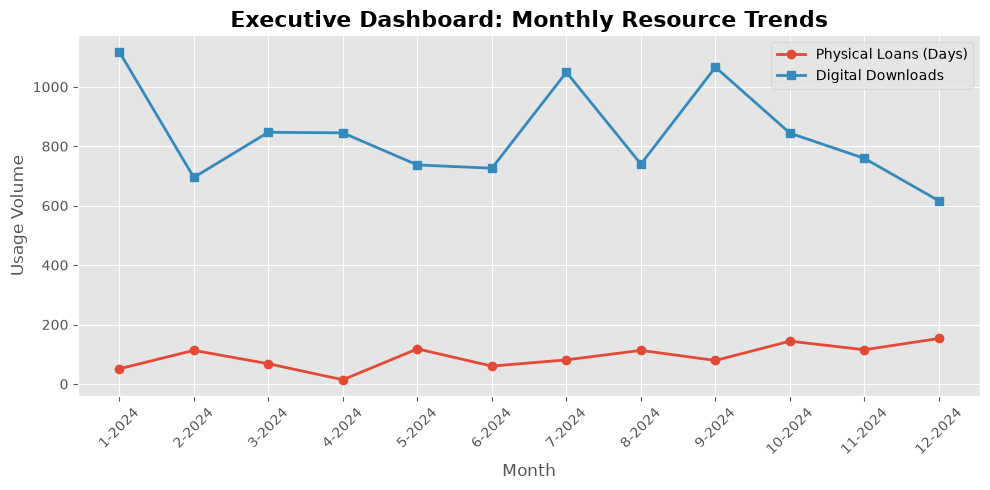

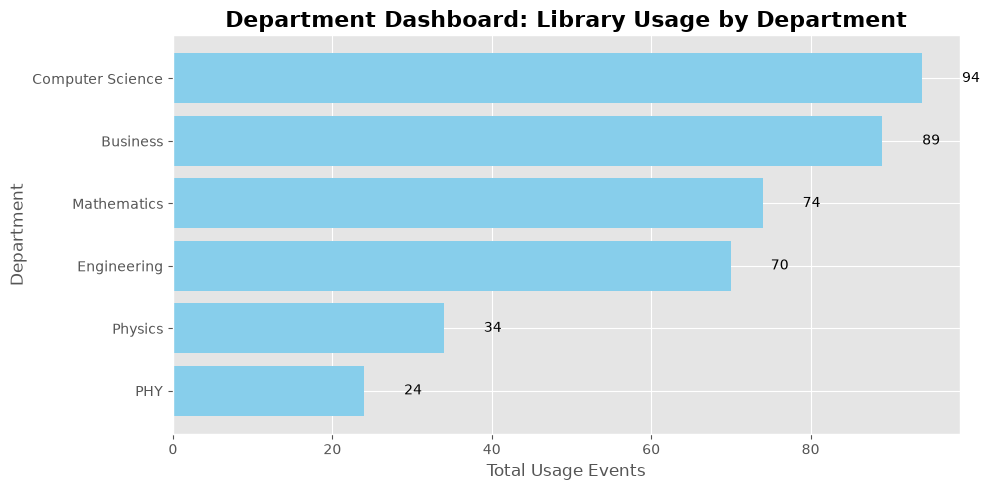

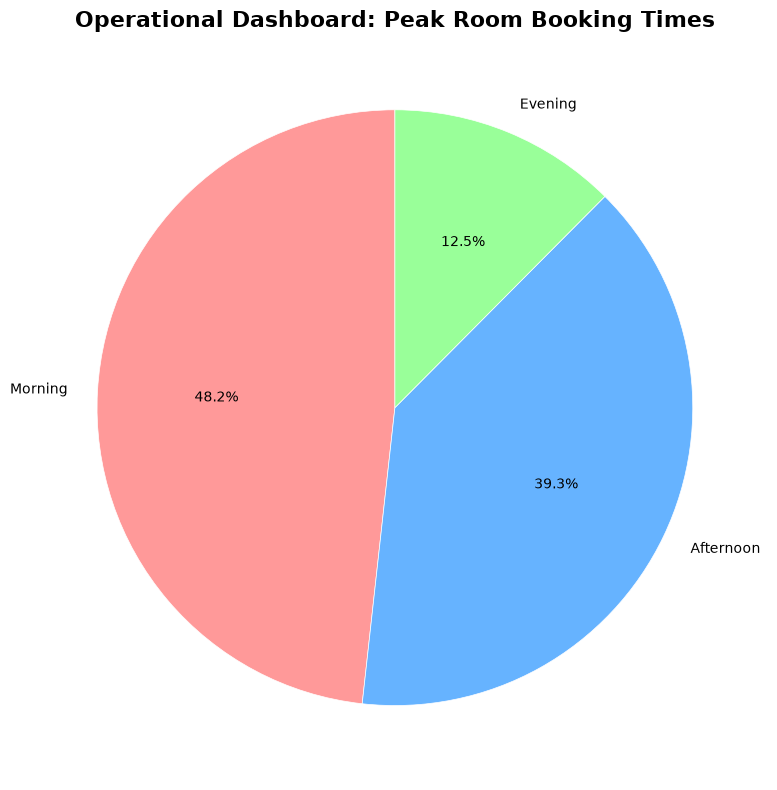

All 3 dashboards saved as PNG images in the '06_Dashboards' folder!


In [87]:
import matplotlib.pyplot as plt
import os

# Ensure the folder exists
os.makedirs('06_Dashboards', exist_ok=True)

# Set a nice style
plt.style.use('ggplot')

# --- DASHBOARD 1: Executive (Monthly Trends) ---
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(q1['month'].astype(str) + '-' + q1['year'].astype(str), q1['physical_loan_days'], marker='o', label='Physical Loans (Days)', linewidth=2)
ax.plot(q1['month'].astype(str) + '-' + q1['year'].astype(str), q1['digital_downloads'], marker='s', label='Digital Downloads', linewidth=2)

ax.set_title('Executive Dashboard: Monthly Resource Trends', fontsize=16, fontweight='bold')
ax.set_xlabel('Month', fontsize=12)
ax.set_ylabel('Usage Volume', fontsize=12)
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('06_Dashboards/Executive_Dashboard.png')
plt.show()

# --- DASHBOARD 2: Department Analysis (Bar Chart) ---
fig, ax = plt.subplots(figsize=(10, 5))
q2_plot = q2.head(8) # Top 8 departments
bars = ax.barh(q2_plot['department'], q2_plot['usage_events'], color='skyblue')
ax.invert_yaxis()  # highest at the top

ax.set_title('Department Dashboard: Library Usage by Department', fontsize=16, fontweight='bold')
ax.set_xlabel('Total Usage Events', fontsize=12)
ax.set_ylabel('Department', fontsize=12)

# Add numbers to the end of the bars
for bar in bars:
    ax.text(bar.get_width() + 5, bar.get_y() + bar.get_height()/2, 
            f'{int(bar.get_width())}', va='center', fontsize=10)

plt.tight_layout()
plt.savefig('06_Dashboards/Department_Dashboard.png')
plt.show()

# --- DASHBOARD 3: Operational (Peak Times) ---
fig, ax = plt.subplots(figsize=(8, 8))
colors = ['#ff9999','#66b3ff','#99ff99']
ax.pie(q3['bookings'], labels=q3['time_slot'], autopct='%1.1f%%', startangle=90, colors=colors, wedgeprops={'edgecolor': 'white'})
ax.set_title('Operational Dashboard: Peak Room Booking Times', fontsize=16, fontweight='bold')

plt.tight_layout()
plt.savefig('06_Dashboards/Operational_Dashboard.png')
plt.show()

print("All 3 dashboards saved as PNG images in the '06_Dashboards' folder!")

# End